# Mini-Project 5 — Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A matatu association runs 14-seater vehicles on three routes out of Kampala. It wants to forecast demand, understand fares, and decide how many vehicles to deploy.

**Data.** Daily passenger counts over 10 days. Kampala–Ntinda comes from the original question; Entebbe and Mukono are illustrative.

**Assumptions**
- Passenger counts are the route's total daily passengers (both directions).
- "Best model" is judged by one-step-ahead **walk-forward** MAE over days 4–10. Every forecast only uses days before the day being forecast.
- The SES smoothing parameter α is tuned by grid search (0.05 to 1.00, step 0.05) on the same walk-forward window, per route.

Code: `src/taxi.py` (`Route`, `LinearMarket`, forecasters, `FleetPlanner`). The `Forecaster` base class and `LinearTrendForecaster` are **reused** from `src/common/forecasting.py` (shared with Mini-Project 1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.taxi import (
    Route, LinearMarket, MovingAverageForecaster, SimpleExponentialSmoothing, SeasonalNaiveForecaster,
    FleetPlanner, backtest_mae, tune_alpha, simulate_weekly_demand, default_models,
)
from src.common.forecasting import LinearTrendForecaster, walk_forward_predictions, mae

SEED = 2026
pd.set_option("display.float_format", "{:,.2f}".format)
routes = [
    Route("Kampala-Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2000),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5000),
    Route("Kampala-Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3000),
]
DAYS = np.arange(1, 11)

## Task 1 — The `Route` class: revenue and descriptive statistics

In [2]:
for r in routes:
    print(r)
rev = pd.DataFrame({r.name: r.daily_revenue() for r in routes}, index=pd.Index(DAYS, name="Day"))
display(rev.style.format("{:,.0f}").set_caption("Daily revenue (UGX)"))

desc = pd.DataFrame([{"Route": r.name, "Fare (UGX)": r.fare, **{f"passengers {k}": v for k, v in r.describe().items()},
                      "CV": r.describe()["std"] / r.describe()["mean"], "Total revenue (UGX)": r.total_revenue()}
                     for r in routes]).set_index("Route")
desc

Route('Kampala-Ntinda', days=10, fare=UGX 2,000)
Route('Kampala-Entebbe', days=10, fare=UGX 5,000)
Route('Kampala-Mukono', days=10, fare=UGX 3,000)


,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
Day,,,
1,"70,000","300,000","135,000"
2,"80,000","290,000","141,000"
3,"84,000","325,000","150,000"
4,"100,000","350,000","147,000"
5,"110,000","360,000","165,000"
6,"120,000","400,000","186,000"
7,"96,000","375,000","174,000"
8,"104,000","340,000","159,000"
9,"94,000","330,000","153,000"


,Fare (UGX),passengers mean,passengers variance,passengers std,CV,Total revenue (UGX)
Route,,,,,,
Kampala-Ntinda,"2,000.00",47.40,54.27,7.37,0.16,"948,000.00"
Kampala-Entebbe,"5,000.00",67.80,45.07,6.71,0.10,"3,390,000.00"
Kampala-Mukono,"3,000.00",52.00,26.44,5.14,0.10,"1,560,000.00"


Entebbe carries the most passengers at the highest fare, so it earns about 3.6× Ntinda's revenue. Ntinda has the most volatile demand (highest variance and CV), largely because of the ramp-up from 35 to 60 passengers in the first six days.

## Task 2 — Supply–demand equilibrium on the Ntinda route

$Q_d = 120 - 0.02P$ and $Q_s = 10 + 0.03P$. At equilibrium $Q_d = Q_s = Q$, which gives the linear system

$$\begin{bmatrix}1 & 0.02\\ 1 & -0.03\end{bmatrix}\begin{bmatrix}Q\\P\end{bmatrix} = \begin{bmatrix}120\\10\end{bmatrix}$$

In [3]:
market = LinearMarket(a=120, b=0.02, c=10, d=0.03)
print(market)
p_star, q_star = market.equilibrium()
print(f"Equilibrium fare  P* = UGX {p_star:,.0f}")
print(f"Equilibrium qty   Q* = {q_star:.0f} passengers per trip-hour")
print(f"Hand check: 110 = 0.05P -> P = {110 / 0.05:,.0f}, Q = 120 - 0.02*2200 = {120 - 0.02 * 2200:.0f}")
current = 2000
print(f"\nAt the current fare UGX {current:,}: demand = {market.demand(current):.0f}, supply = {market.supply(current):.0f}, "
      f"excess demand = {market.excess_demand(current):+.0f} passengers per trip-hour")

LinearMarket(Qd = 120 - 0.02P, Qs = 10 + 0.03P)
Equilibrium fare  P* = UGX 2,200
Equilibrium qty   Q* = 76 passengers per trip-hour
Hand check: 110 = 0.05P -> P = 2,200, Q = 120 - 0.02*2200 = 76

At the current fare UGX 2,000: demand = 80, supply = 70, excess demand = +10 passengers per trip-hour


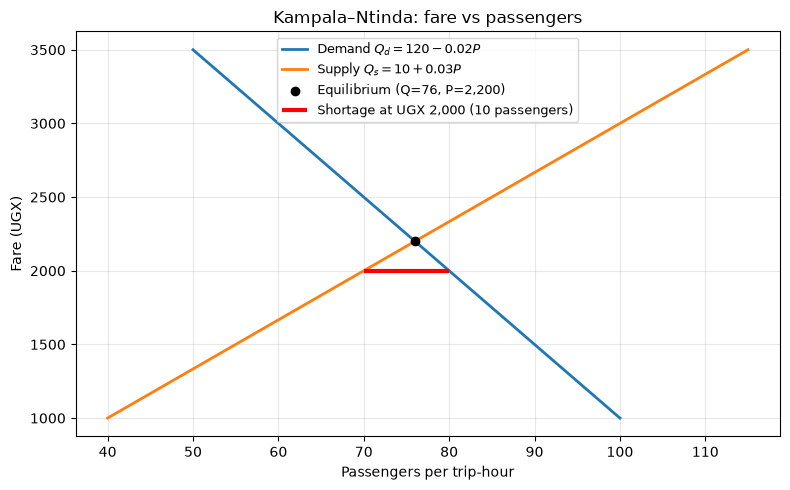

In [4]:
prices = np.linspace(1000, 3500, 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([market.demand(p) for p in prices], prices, label="Demand $Q_d = 120 - 0.02P$", lw=2)
ax.plot([market.supply(p) for p in prices], prices, label="Supply $Q_s = 10 + 0.03P$", lw=2)
ax.scatter([q_star], [p_star], color="black", zorder=5, label=f"Equilibrium (Q={q_star:.0f}, P={p_star:,.0f})")
ax.hlines(current, market.supply(current), market.demand(current), color="red", lw=3,
          label=f"Shortage at UGX 2,000 ({market.excess_demand(current):.0f} passengers)")
ax.set(xlabel="Passengers per trip-hour", ylabel="Fare (UGX)", title="Kampala–Ntinda: fare vs passengers")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p5_equilibrium.png", dpi=150); plt.show()

**Interpretation.** The market-clearing fare is **UGX 2,200** with 76 passengers per trip-hour. The current UGX 2,000 fare is **UGX 200 below equilibrium**. At that fare 80 people want to ride but operators only offer 70 seats, a **shortage of 10 passengers per trip-hour**. In practice this shows up as queues at the stage, overloading, or conductors charging unofficial extra fares at peak times. Options: raise the fare towards 2,200, which closes the gap but loses some riders, or keep the fare and add supply (more vehicles or trips), which shifts the supply curve right. Given the fleet analysis below, adding trips is feasible.

## Task 3 — The forecasters

| Model | Class | Forecast for tomorrow |
|---|---|---|
| (a) 3-day moving average (original) | `MovingAverageForecaster(3)` | mean of the last 3 days |
| (b) Simple exponential smoothing | `SimpleExponentialSmoothing(α)` | last smoothed level $\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}$ |
| (c) Linear trend | `LinearTrendForecaster` (shared with Project 1) | least-squares line extended one day |
| (ext.) Seasonal naïve | `SeasonalNaiveForecaster(7)` | the same weekday last week |

All subclass the abstract `Forecaster`, so the backtesting code treats them identically.

## Task 4 — Walk-forward backtesting (days 4–10) and tuning α

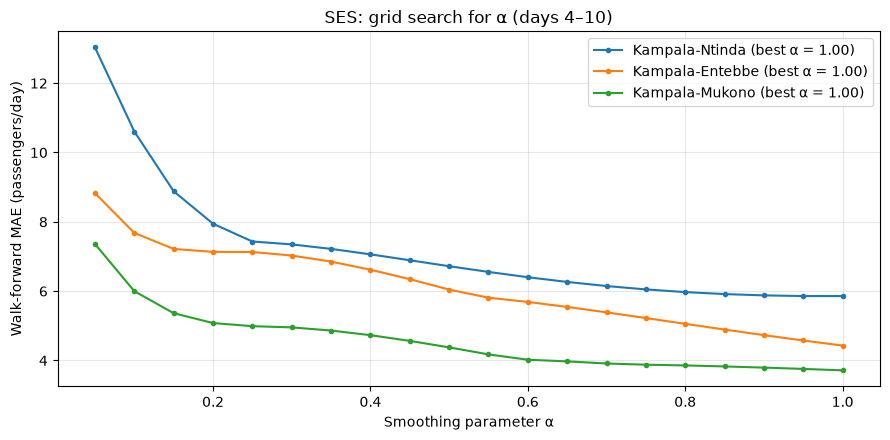

In [5]:
alpha_grid = np.round(np.arange(0.05, 1.0001, 0.05), 2)
best_alpha, alpha_scores = {}, {}
for r in routes:
    best_alpha[r.name], alpha_scores[r.name] = tune_alpha(r.passengers, grid=alpha_grid, first_day=4)

fig, ax = plt.subplots(figsize=(9, 4.5))
for r in routes:
    s = alpha_scores[r.name]
    ax.plot(list(s.keys()), list(s.values()), "o-", ms=3, label=f"{r.name} (best α = {best_alpha[r.name]:.2f})")
ax.set(xlabel="Smoothing parameter α", ylabel="Walk-forward MAE (passengers/day)", title="SES: grid search for α (days 4–10)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p5_alpha_grid.png", dpi=150); plt.show()

In [6]:
mae_rows = []
for r in routes:
    models = default_models(alpha=best_alpha[r.name])
    row = {"Route": r.name}
    for name, factory in models.items():
        row[name] = backtest_mae(factory, r.passengers, first_day=4)
    mae_rows.append(row)
mae_df = pd.DataFrame(mae_rows).set_index("Route")
mae_df["Best model"] = mae_df.idxmin(axis=1)
mae_df["Best α"] = pd.Series(best_alpha)
mae_df

,3-day moving average,SES,Linear trend,Best model,Best α
Route,,,,,
Kampala-Ntinda,7.52,5.86,7.87,SES,1.00
Kampala-Entebbe,7.19,4.43,7.71,SES,1.00
Kampala-Mukono,5.33,3.71,6.39,SES,1.00


In [7]:
# Hand check: 3-day MA on Ntinda, day 4 forecast = mean(35, 40, 42) = 39, actual 50 -> error 11
ntinda = routes[0].passengers
ma_preds = walk_forward_predictions(lambda: MovingAverageForecaster(3), ntinda, first_index=3)
print("MA(3) forecasts for days 4-10:", ma_preds.round(2))
print("Actual days 4-10:            ", ntinda[3:])
print(f"MAE = {np.mean(np.abs(ntinda[3:] - ma_preds)):.2f}  (matches table: {mae_df.loc['Kampala-Ntinda', '3-day moving average']:.2f})")

MA(3) forecasts for days 4-10: [39.   44.   49.   55.   54.33 53.33 49.  ]
Actual days 4-10:             [50. 55. 60. 48. 52. 47. 45.]
MAE = 7.52  (matches table: 7.52)


**Reading the results.** The grid search picks **α = 1.00 on every route**. At α = 1, SES simply forecasts *yesterday's value* (the naïve forecast). This tells us something about the data: over these 10 days, demand behaves like a **random walk**. The best guess for tomorrow is today, and averaging older days (moving average, small α) or fitting a line only adds lag. The 3-day MA is always behind because it averages in days from before the mid-series peak. The linear trend is pulled by the early ramp-up from day 1 to day 6 and keeps projecting growth that stopped after day 6.

A caution: α was chosen and evaluated on the **same 7 days**, so the SES error is optimistic (a mild form of overfitting). With more data we would tune α on one window and evaluate on a later one.

## Task 5 — Day-11 revenue forecast with the best model

In [8]:
planner = FleetPlanner(trips_per_day=8, seats=14, buffer=0.15)
fc_rows, backtests = [], {}
for r in routes:
    best = mae_df.loc[r.name, "Best model"]
    factory = default_models(alpha=best_alpha[r.name])[best]
    backtests[r.name] = walk_forward_predictions(factory, r.passengers, first_index=3)
    pax11 = factory().fit(r.passengers).predict(1)[0]
    fc_rows.append({"Route": r.name, "Model": best if best != "SES" else f"SES (α={best_alpha[r.name]:.2f})",
                    "Day-11 passengers": pax11, "Day-11 revenue (UGX)": pax11 * r.fare,
                    "Backtest MAE (UGX)": mae_df.loc[r.name, best] * r.fare})
fc_df = pd.DataFrame(fc_rows).set_index("Route")
fc_df

,Model,Day-11 passengers,Day-11 revenue (UGX),Backtest MAE (UGX)
Route,,,,
Kampala-Ntinda,SES (α=1.00),45.00,"90,000.00","11,714.29"
Kampala-Entebbe,SES (α=1.00),64.00,"320,000.00","22,142.86"
Kampala-Mukono,SES (α=1.00),50.00,"150,000.00","11,142.86"


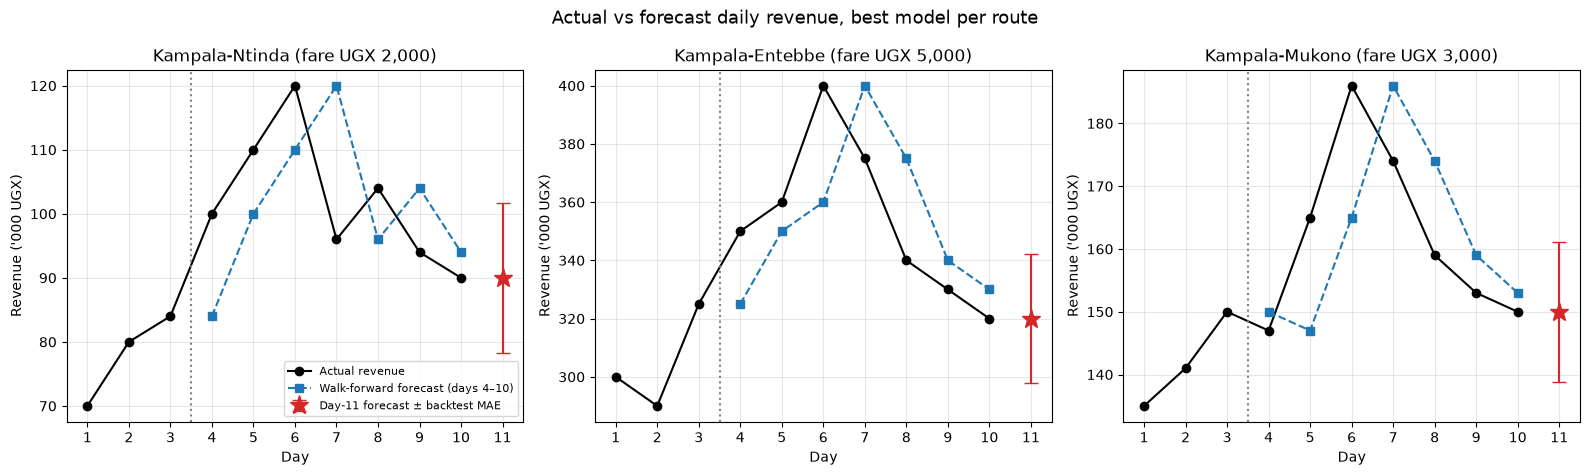

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True)
for ax, r in zip(axes, routes):
    ax.plot(DAYS, r.daily_revenue() / 1000, "o-", color="black", label="Actual revenue")
    ax.plot(DAYS[3:], backtests[r.name] * r.fare / 1000, "s--", color="tab:blue", label="Walk-forward forecast (days 4–10)")
    d11 = fc_df.loc[r.name, "Day-11 revenue (UGX)"] / 1000
    err = fc_df.loc[r.name, "Backtest MAE (UGX)"] / 1000
    ax.errorbar([11], [d11], yerr=[[err], [err]], fmt="*", ms=14, color="tab:red", capsize=5, label="Day-11 forecast ± backtest MAE")
    ax.axvline(3.5, color="grey", ls=":")
    ax.set(title=f"{r.name} (fare UGX {r.fare:,.0f})", xlabel="Day", ylabel="Revenue ('000 UGX)")
    ax.set_xticks(range(1, 12)); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Actual vs forecast daily revenue, best model per route", fontsize=13)
fig.tight_layout(); fig.savefig("figures/p5_revenue_forecast.png", dpi=150); plt.show()

## Task 6 — Fleet planning for day 11

Each vehicle carries $8 \times 14 = 112$ passengers a day. Vehicles $= \lceil \text{forecast} \times 1.15 / 112 \rceil$. We **round up**, because a fraction of a vehicle cannot be deployed and rounding down would strand passengers.

In [10]:
fleet = []
for r in routes:
    pax = fc_df.loc[r.name, "Day-11 passengers"]
    v = planner.vehicles_needed(pax)
    fleet.append({"Route": r.name, "Forecast passengers": pax, "With 15% buffer": pax * 1.15,
                  "Vehicles needed": v, "Seat capacity": v * planner.daily_capacity_per_vehicle,
                  "Expected load factor": planner.load_factor(pax, v),
                  "Peak day in data": r.passengers.max(), "Vehicles for peak day": planner.vehicles_needed(r.passengers.max())})
fleet_df = pd.DataFrame(fleet).set_index("Route")
fleet_df.style.format({"Forecast passengers": "{:.1f}", "With 15% buffer": "{:.1f}", "Expected load factor": "{:.0%}"})

,Forecast passengers,With 15% buffer,Vehicles needed,Seat capacity,Expected load factor,Peak day in data,Vehicles for peak day
Route,,,,,,,
Kampala-Ntinda,45.0,51.7,1,112,40%,60.000000,1
Kampala-Entebbe,64.0,73.6,1,112,57%,80.000000,1
Kampala-Mukono,50.0,57.5,1,112,45%,62.000000,1


**Interpretation.** **One vehicle per route** is enough on day 11. Even the busiest route (Entebbe, about 74 passengers after the buffer) fills only about two thirds of one vehicle's 112 daily seats, and one vehicle also covers the busiest day in the data. "Sensible rounding" here means rounding up to whole vehicles, never down.

This result also questions the data. A real Kampala route would carry thousands of passengers a day, so the counts are more plausibly passengers *per vehicle* or per trip-hour. The Task 2 demand model supports this: it is expressed per trip-hour and gives about 76 passengers. If the counts were per trip-hour over, say, a 12-hour operating day, Entebbe would need about $\lceil 64 \times 12 \times 1.15 / 112 \rceil = 8$ vehicles. The association should confirm what the counts measure before acting on the fleet numbers.

## Extension — 60 days with a weekly pattern: seasonal naïve vs moving average

In [11]:
sim_days = 60
first_day = 15                                   # need 2 weeks of history before evaluating
sim, ext_rows, ext_preds = {}, [], {}
for r in routes:
    y = simulate_weekly_demand(base=r.passengers.mean(), days=sim_days, noise_sd=0.05, seed=SEED)
    sim[r.name] = y
    a_best, _ = tune_alpha(y, first_day=first_day)
    models = {
        "3-day moving average": lambda: MovingAverageForecaster(3),
        f"SES (α={a_best:.2f})": lambda a=a_best: SimpleExponentialSmoothing(a),
        "Linear trend": LinearTrendForecaster,
        "Seasonal naïve (m=7)": lambda: SeasonalNaiveForecaster(7),
    }
    row = {"Route": r.name}
    for name, f in models.items():
        preds = walk_forward_predictions(f, y, first_index=first_day - 1)
        row[name.split(" (")[0] if name.startswith("SES") else name] = mae(y[first_day - 1:], preds)
        ext_preds[(r.name, name)] = preds
    ext_rows.append(row)
ext_df = pd.DataFrame(ext_rows).set_index("Route")
ext_df["Best"] = ext_df.idxmin(axis=1)
ext_df["MA error ÷ seasonal-naïve error"] = ext_df["3-day moving average"] / ext_df["Seasonal naïve (m=7)"]
print("Weekday multipliers used (Mon..Sun):", [1.00, 0.95, 1.00, 1.05, 1.35, 1.10, 0.60])
ext_df

Weekday multipliers used (Mon..Sun): [1.0, 0.95, 1.0, 1.05, 1.35, 1.1, 0.6]


,3-day moving average,SES,Linear trend,Seasonal naïve (m=7),Best,MA error ÷ seasonal-naïve error
Route,,,,,,
Kampala-Ntinda,9.25,6.97,7.13,2.39,Seasonal naïve (m=7),3.87
Kampala-Entebbe,13.20,9.95,10.14,3.52,Seasonal naïve (m=7),3.75
Kampala-Mukono,10.17,7.64,7.84,2.70,Seasonal naïve (m=7),3.77


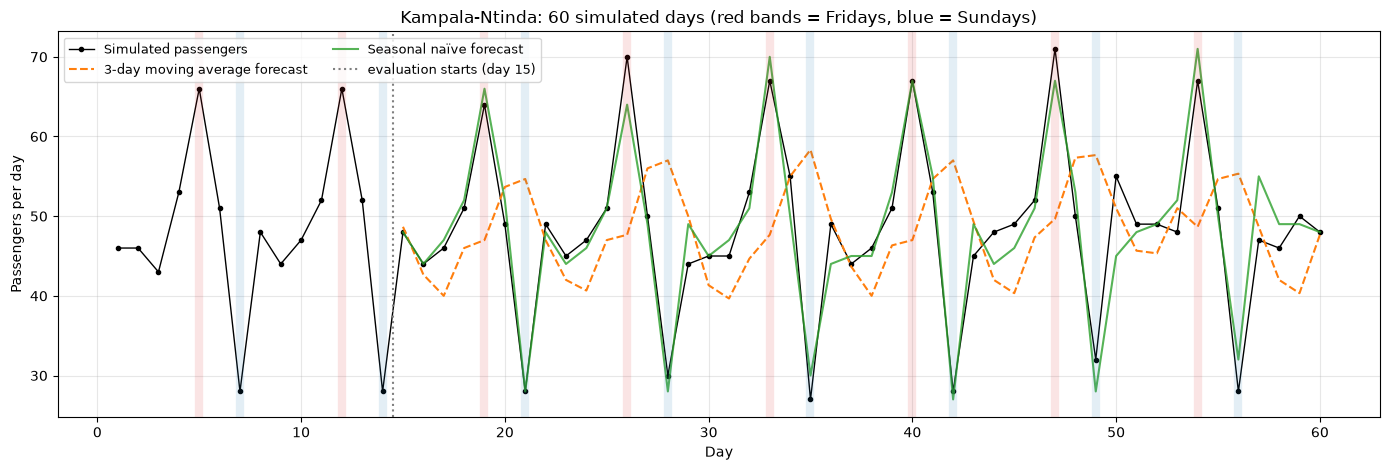

In [12]:
name = "Kampala-Ntinda"
y = sim[name]
d = np.arange(1, sim_days + 1)
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(d, y, "o-", color="black", ms=3, lw=1, label="Simulated passengers")
ax.plot(d[first_day - 1:], ext_preds[(name, "3-day moving average")], "--", color="tab:orange", label="3-day moving average forecast")
ax.plot(d[first_day - 1:], ext_preds[(name, "Seasonal naïve (m=7)")], "-", color="tab:green", alpha=0.8, label="Seasonal naïve forecast")
for fri in d[(d - 1) % 7 == 4]:
    ax.axvline(fri, color="tab:red", alpha=0.12, lw=6)
for sun in d[(d - 1) % 7 == 6]:
    ax.axvline(sun, color="tab:blue", alpha=0.12, lw=6)
ax.axvline(first_day - 0.5, color="grey", ls=":", label="evaluation starts (day 15)")
ax.set(title=f"{name}: 60 simulated days (red bands = Fridays, blue = Sundays)", xlabel="Day", ylabel="Passengers per day")
ax.legend(fontsize=9, ncol=2); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p5_seasonal_naive.png", dpi=150); plt.show()

**Why seasonal naïve wins.** With a strong weekly cycle, the best predictor of Friday is *last Friday*, not the average of Tuesday–Thursday. The moving average always lags and smooths the pattern: it under-forecasts every Friday peak and over-forecasts every Sunday, so its error is several times larger than seasonal naïve's on all three routes. SES and the linear trend have the same blind spot, because none of them knows what day of the week it is. A model is only as good as the structure it can represent. In practice the association should forecast by weekday (and could combine seasonality with a trend, e.g. Holt-Winters).

## Findings & Limitations

**Findings.** *Pricing:* on Kampala–Ntinda the UGX 2,000 fare is UGX 200 below the market-clearing UGX 2,200. At that fare there is a shortage of about 10 passengers per trip-hour, so the association should raise fares modestly or add trips. *Forecasting:* over these 10 days the simplest forecast won. Tuned SES chose α = 1 on every route, which is "tomorrow = today". It beat the original 3-day moving average by 22–38 % in MAE, because demand rose to a day-6 peak and then fell, and both averaging and trend-fitting lag behind turning points. Forecasting day 11 with it gives revenue of about UGX 90k (Ntinda), 320k (Entebbe) and 150k (Mukono), with typical errors of ±11–22k. *Fleet:* one 14-seater making 8 trips (112 seats) covers each route's day-11 demand plus a 15 % buffer. This suggests the counts are per vehicle or per trip-hour rather than route totals, and the association should check that before acting. *Extension:* once a weekly cycle exists (busy Fridays, quiet Sundays), seasonal naïve cut the moving average's error by nearly 4× on every route. The lesson is to forecast by weekday.

**Limitations.** (1) Ten days is far too little data. The backtest has only 7 forecasts, α was tuned and scored on the same days (optimistic), and the "α = 1" result may not survive a longer sample. (2) The demand/supply equations are given, not estimated, and are linear. Real responses depend on fuel prices and competition (boda-bodas). (3) Fleet sizing assumes demand is spread evenly over the day. Real demand peaks at rush hour, which drives fleet size. (4) The 60-day data are simulated with a weekly pattern we chose, so the extension shows that seasonal naïve works *when* such a pattern exists, not that it exists on these routes.